# Etapa 2 - Análise exploratória: Bolsa Família, Auxílio Brasil e Novo Bolsa Família (2019 a 2026)

Nessa etapa o objetivo foi conhecer a base e encontrar os problemas que a limpeza vai tratar. O recorte (ficha em
`reports/ficha_semana1.md`) são os pagamentos das três fases do programa federal de transferência de renda, de janeiro
de 2019 a setembro de 2026, nas 27 UFs, com cerca de 1,65 bilhão de linhas (15,9 GB em Parquet).

Como a base não cabe na memória, nenhuma célula carrega ela inteira. O script `src/eda.py` percorre a bronze um
arquivo mensal por vez com DuckDB e grava resumos pequenos em `data/_eda/` (perfil das colunas, totais mensais,
município por mês, faixas de valor, defasagem dos pagamentos e entradas e saídas de famílias), e esse notebook lê esses
resumos e, quando precisa de linhas individuais, uma amostra aleatória de 1 milhão de pagamentos. Antes de rodar, é
preciso rodar `python src/eda.py` na raiz do projeto (de 1 a 3 horas na primeira vez, e depois ele só refaz o que
mudou na bronze), e os textos de leitura citam os números dessa execução, com dados até setembro de 2026.

O notebook segue a ordem visão geral, qualidade, análise univariada, análise bivariada e temporal, respostas
preliminares às 5 perguntas e, por fim, a lista priorizada de problemas para a limpeza.

In [1]:
from pathlib import Path
from decimal import Decimal
import io

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EDA = RAIZ / "data" / "_eda"
BRONZE = RAIZ / "data" / "bronze"
REF = BRONZE / "referencias"

FASES = ["Bolsa Família", "Auxílio Brasil", "Novo Bolsa Família"]
# paleta categórica validada (3 primeiras posições: passam no teste de daltonismo em todos os pares)
COR = {"Bolsa Família": "#2a78d6", "Auxílio Brasil": "#eb6834", "Novo Bolsa Família": "#1baf7a"}
TINTA, TINTA_2, MUDO, GRADE, EIXO, FUNDO = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
POSITIVO, NEUTRO, NEGATIVO = "#2a78d6", "#f0efec", "#e34948"  # par divergente (polaridade)
DIVERGENTE = LinearSegmentedColormap.from_list("div", [NEGATIVO, NEUTRO, POSITIVO])
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "axes.edgecolor": EIXO, "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA, "axes.grid": True,
    "grid.color": GRADE, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "text.parse_math": False,  # "R$ 170 ... R$ 650" não é fórmula
})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
MARCOS = {"2020-03": "pandemia", "2021-11": "Auxílio Brasil", "2023-03": "Novo Bolsa Família"}

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")


def _decimais_para_float(df):
    for c in df.columns:
        amostra = df[c].dropna().head(1)
        if len(amostra) and isinstance(amostra.iloc[0], Decimal):
            df[c] = df[c].astype(float)
    return df


def sql(consulta):
    return _decimais_para_float(con.execute(consulta).fetchdf())


def ler(tabela):
    pasta = EDA / tabela
    if not any(pasta.glob("*.parquet")):
        raise FileNotFoundError(f"Falta {pasta.relative_to(RAIZ)}: rode antes `python src/eda.py` na raiz do projeto")
    df = sql(f"SELECT * FROM read_parquet('{(pasta / '*.parquet').as_posix()}', union_by_name = true)")
    if "periodo" in df:
        df["data"] = pd.to_datetime(df.periodo.astype(str), format="%Y%m")
        df["ano"] = df.periodo.astype(str).str[:4].astype(int)
    if "fase" in df:
        df["fase"] = pd.Categorical(df.fase, FASES, ordered=True)
    return df


def br(x, casas=0):
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")


def mi(x, casas=1):
    return br(x / 1e6, casas) + " mi"


def pct(x, casas=1):
    return br(100 * x, casas) + "%"


def marcar_transicoes(ax, rotulos=True):
    for m, nome in MARCOS.items():
        x = pd.Timestamp(m + "-01")
        ax.axvline(x, color=EIXO, lw=1, ls="--", zorder=0)
        if rotulos:
            ax.annotate(nome, (x, 1), xycoords=("data", "axes fraction"), xytext=(3, -2),
                        textcoords="offset points", va="top", fontsize=8, color=TINTA_2)


perfil, mensal, mun = ler("perfil"), ler("mensal"), ler("municipio_mes")
faixas, defas, trans = ler("valor_faixas"), ler("defasagem"), ler("transicoes")
# só pares de meses consecutivos: um par com lacuna no meio mediria dois meses de fluxo
seguinte = (pd.to_datetime(trans.periodo_anterior, format="%Y%m") + pd.DateOffset(months=1)).dt.strftime("%Y%m")
trans = trans[trans.periodo == seguinte].copy()
q = pd.DataFrame(mensal.valor_quantis.tolist(), columns=["p01", "p05", "p25", "p50", "p75", "p95", "p99"]).astype(float)
mensal = pd.concat([mensal.drop(columns="valor_quantis"), q], axis=1)
print(f"Resumos lidos: {mensal.periodo.nunique()} meses ({mensal.periodo.min()} a {mensal.periodo.max()}), "
      f"{len(mensal)} arquivos mensais, {len(mun):,} linhas município × mês".replace(",", "."))

Resumos lidos: 93 meses (201901 a 202609). 94 arquivos mensais. 523.592 linhas município × mês


## 1. Visão geral

### 1.1 Dimensões

In [2]:
dim = (mensal.groupby(["ano", "fase"], observed=True).linhas.sum().unstack("fase"))
dim["Total"] = dim.sum(axis=1)
dim.loc["Total"] = dim.sum()
meses = mensal.groupby("fase", observed=True).agg(meses=("periodo", "nunique"), de=("periodo", "min"),
                                                   ate=("periodo", "max"), linhas=("linhas", "sum"))
print(f"Linhas no recorte: {br(mensal.linhas.sum())} em {mensal.periodo.nunique()} meses "
      f"({len(mensal)} arquivos; nov/2021 tem um arquivo de cada uma das duas primeiras fases)")
print("Colunas por linha: 8 do Portal (mês de competência, mês de referência, UF, código SIAFI e nome do município,"
      " CPF mascarado, NIS, valor da parcela)")
display(meses)
display(dim.map(lambda v: "" if pd.isna(v) else br(v)))

Linhas no recorte: 1.647.824.350 em 93 meses (94 arquivos; nov/2021 tem um arquivo de cada uma das duas primeiras fases)
Colunas por linha: 8 do Portal (mês de competência, mês de referência, UF, código SIAFI e nome do município, CPF mascarado, NIS, valor da parcela)


,meses,de,ate,linhas
fase,,,,
Bolsa Família,35,201901,202111,494674172
Auxílio Brasil,16,202111,202302,293956157
Novo Bolsa Família,43,202303,202609,859194021


fase,Bolsa Família,Auxílio Brasil,Novo Bolsa Família,Total
ano,,,,
2019,166.265.772,,,166.265.772
2020,168.213.073,,,168.213.073
2021,160.195.327,28.540.319,,188.735.646
2022,,222.756.535,,222.756.535
2023,,42.659.303,205.070.502,247.729.805
2024,,,248.202.310,248.202.310
2025,,,234.426.428,234.426.428
2026,,,171.494.781,171.494.781
Total,494.674.172,293.956.157,859.194.021,1.647.824.350


### 1.2 Tipos inferidos × tipos esperados e uso de memória

Na bronze todas as colunas foram gravadas como texto (`VARCHAR`) de propósito, para nenhuma conversão acontecer antes
de a EDA mostrar o que tem em cada coluna. Essa célula pega uma amostra de 1 milhão de pagamentos e relê com o
`pandas.read_csv`, para ver qual tipo o pandas escolheria sozinho, e compara com o tipo esperado pelo dicionário e com
a memória de cada coluna.

In [3]:
COLS = {"MÊS COMPETÊNCIA": "mes_competencia", "MÊS REFERÊNCIA": "mes_referencia", "UF": "uf",
        "CÓDIGO MUNICÍPIO SIAFI": "cod_siafi", "NOME MUNICÍPIO": "nome_municipio", "CPF FAVORECIDO": "cpf",
        "NIS FAVORECIDO": "nis", "VALOR PARCELA": "valor"}
sel = ", ".join(f'"{a}" AS {b}' for a, b in COLS.items())
P = mensal[mensal.fase == "Novo Bolsa Família"].periodo.max()
padrao = (BRONZE / "novo_bolsa_familia" / "novo_bolsa_familia" / f"ano={P[:4]}" / "uf_sigla=*" / f"{P}.parquet").as_posix()
tipos_bronze = sql(f"DESCRIBE SELECT {sel} FROM read_parquet('{padrao}')").set_index("column_name").column_type
amostra = sql(f"SELECT {sel} FROM read_parquet('{padrao}') USING SAMPLE reservoir(1000000 ROWS) REPEATABLE (42)")
amostra = amostra.astype(object)
inferido = pd.read_csv(io.StringIO(amostra.head(200_000).to_csv(sep=";", index=False)), sep=";").dtypes.astype(str)

tipado = pd.DataFrame({
    "mes_competencia": pd.to_datetime(amostra.mes_competencia, format="%Y%m"),
    "mes_referencia": pd.to_datetime(amostra.mes_referencia, format="%Y%m"),
    "uf": amostra.uf.astype("category"),
    "cod_siafi": amostra.cod_siafi.astype("category"),
    "nome_municipio": amostra.nome_municipio.astype("category"),
    "cpf": amostra.cpf.astype("string"),
    "nis": pd.to_numeric(amostra.nis, errors="coerce").astype("Int64"),
    "valor": pd.to_numeric(amostra.valor.str.replace(".", "", regex=False).str.replace(",", ".", regex=False),
                           errors="coerce").astype("float32"),
})
ESPERADO = {"mes_competencia": "mês (data AAAA-MM)", "mes_referencia": "mês (data AAAA-MM)",
            "uf": "categoria (27 siglas)", "cod_siafi": "código de 4 dígitos, com zero à esquerda",
            "nome_municipio": "categoria", "cpf": "texto mascarado ***.000.000-**",
            "nis": "identificador de 11 dígitos", "valor": "decimal em R$ (vírgula decimal)"}
mem_txt = amostra.memory_usage(deep=True, index=False) / 2**20
mem_tip = tipado.memory_usage(deep=True, index=False) / 2**20
tipos = pd.DataFrame({"bronze (Parquet)": tipos_bronze, "pandas.read_csv infere": inferido,
                      "esperado (dicionário)": pd.Series(ESPERADO), "tipo proposto": tipado.dtypes.astype(str),
                      "memória texto (MB)": mem_txt.round(1), "memória tipada (MB)": mem_tip.round(1)})
tipos.loc["Total", ["memória texto (MB)", "memória tipada (MB)"]] = [mem_txt.sum().round(1), mem_tip.sum().round(1)]
print(f"Amostra: 1.000.000 de pagamentos do Novo Bolsa Família de {P[4:]}/{P[:4]}")
print(f"Memória da amostra como texto: {br(mem_txt.sum(), 1)} MB → tipada: {br(mem_tip.sum(), 1)} MB "
      f"({pct(1 - mem_tip.sum() / mem_txt.sum())} menor). Na base inteira (1,65 bi linhas) a versão texto "
      f"ocuparia ≈ {br(mem_txt.sum() * 1650 / 1024, 0)} GB de RAM; a tipada ≈ {br(mem_tip.sum() * 1650 / 1024, 0)} GB.")
display(tipos.fillna(""))

Amostra: 1.000.000 de pagamentos do Novo Bolsa Família de 09/2026
Memória da amostra como texto: 424,3 MB → tipada: 50,8 MB (88,0% menor). Na base inteira (1,65 bi linhas) a versão texto ocuparia ≈ 684 GB de RAM; a tipada ≈ 82 GB.


,bronze (Parquet),pandas.read_csv infere,esperado (dicionário),tipo proposto,memória texto (MB),memória tipada (MB)
mes_competencia,VARCHAR,int64,mês (data AAAA-MM),datetime64[us],52.5,7.6
mes_referencia,VARCHAR,int64,mês (data AAAA-MM),datetime64[us],52.5,7.6
uf,VARCHAR,str,categoria (27 siglas),category,48.6,1.0
cod_siafi,VARCHAR,int64,"código de 4 dígitos, com zero à esquerda",category,50.5,2.0
nome_municipio,VARCHAR,str,categoria,category,56.8,2.0
cpf,VARCHAR,str,texto mascarado ***.000.000-**,string,53.7,18.2
nis,VARCHAR,float64,identificador de 11 dígitos,Int64,57.2,8.6
valor,VARCHAR,str,decimal em R$ (vírgula decimal),float32,52.5,3.8
Total,,,,,424.3,50.8


Podemos notar que, deixado por conta própria, o pandas erra o tipo de cinco das oito colunas, porque os dois meses
viram inteiros (`202609`) e não datas, o código SIAFI vira inteiro e perde o zero à esquerda (`0123` vira `123`), o
NIS vira `float64` porque há alguns NIS ausentes e a coluna inteira comum do pandas não aceita nulo, e o valor fica
como texto por causa da vírgula decimal. Com os tipos certos (mês como data, UF e município como categoria, NIS como
`Int64` e valor como número) a mesma amostra ocupa 88% menos memória (de 424 para 51 MB por milhão de linhas), então
a conversão de tipos é a primeira coisa que a limpeza faz, e na silver o valor fica em `DECIMAL(10,2)` para somar os
centavos sem erro de arredondamento.

## 2. Qualidade

### 2.1 Ausentes por coluna e por ano

Percentual de valores nulos ou vazios. O Parquet bronze grava campo vazio do CSV como nulo.

ano,2019,2020,2021,2022,2023,2024,2025,2026
coluna,,,,,,,,
cod_siafi,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
cpf,0.93,1.03,2.0,9.71,14.61,18.07,19.62,20.33
mes_competencia,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
mes_referencia,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
nis,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
nome_municipio,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
uf,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00
valor,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00


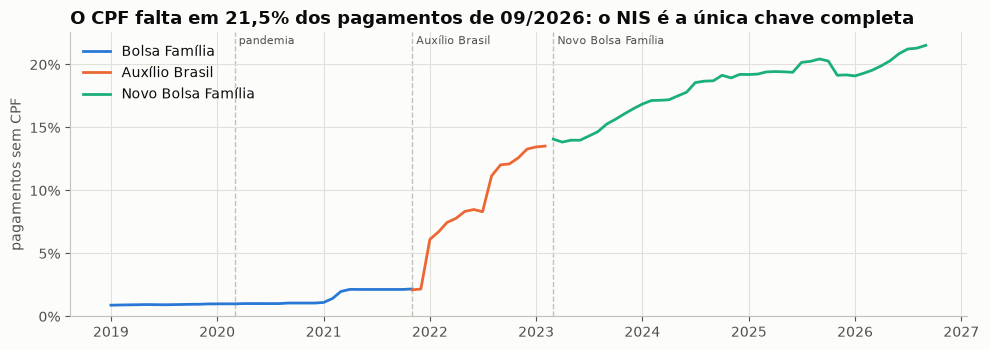

In [4]:
aus = perfil.groupby(["coluna", "ano"], observed=True)[["linhas", "nulos", "vazios"]].sum()
aus = (100 * (aus.nulos + aus.vazios) / aus.linhas).unstack("ano")
display(aus.round(2).rename(index={"valor_txt": "valor"}))

cpf = perfil[perfil.coluna == "cpf"].copy()
cpf["pct"] = 100 * (cpf.nulos + cpf.vazios) / cpf.linhas
fig, ax = plt.subplots(figsize=(10, 3.6))
for f in FASES:
    s = cpf[cpf.fase == f].sort_values("data")
    ax.plot(s.data, s.pct, color=COR[f], label=f)
marcar_transicoes(ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylim(bottom=0)
ax.set_ylabel("pagamentos sem CPF")
fim = cpf.sort_values("data").iloc[-1]
ax.set_title(f"O CPF falta em {br(fim.pct, 1)}% dos pagamentos de {fim.periodo[4:]}/{fim.periodo[:4]}: "
             "o NIS é a única chave completa")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

O CPF é a única coluna com muitos ausentes, e a falta dele cresce com o tempo, indo de 0,9% dos pagamentos em 2019 e
2% em 2021 no Bolsa Família para 13,5% no fim do Auxílio Brasil e 21,5% em setembro de 2026 no Novo Bolsa Família. A
ausência não é aleatória, porque no nível do município quanto menor a cobertura mais falta CPF (seção 4.5,
ρ = −0,60), e como o CPF vem mascarado (`***.123.456-**`) e não serve de chave, a decisão é manter o nulo e criar a
marca `cpf_ausente`, sem imputar nada.

O NIS, que é a chave da família, falta em só 15.601 linhas (0,001%), sendo 6 no Bolsa Família e 15.595 no Novo Bolsa
Família, espalhadas pelos 43 meses dessa fase. Essas linhas ficam fora da contagem de famílias e da busca de
duplicados, mas o valor delas entra nos totais, e as outras seis colunas não têm nenhum ausente.

### 2.2 Duplicados

Aqui conto três coisas em cada arquivo mensal, que são o duplicado exato (a mesma linha inteira repetida), a chave
repetida (o mesmo NIS com o mesmo mês de referência mais de uma vez, ou seja, a mesma parcela paga duas vezes ou
registrada em duas linhas) e o NIS em mais de um município no mesmo mês. Os pagamentos retroativos (mês de referência
anterior ao mês pago) não são duplicados, porque uma família pode receber no mesmo mês a parcela do mês e parcelas
atrasadas (seção 4.3).

In [5]:
dup = mensal.groupby("fase", observed=True).agg(
    linhas=("linhas", "sum"), duplicadas_exatas=("linhas_duplicadas_exatas", "sum"),
    chaves_repetidas=("chaves_repetidas", "sum"), linhas_em_chave_repetida=("linhas_em_chave_repetida", "sum"),
    nis_em_mais_de_um_municipio=("nis_em_mais_de_um_municipio", "sum"))
dup["% linhas em chave repetida"] = (100 * dup.linhas_em_chave_repetida / dup.linhas).round(4)
display(dup)
pior = mensal.sort_values("linhas_em_chave_repetida", ascending=False).head(5)
display(pior[["fase", "periodo", "linhas", "chaves_repetidas", "linhas_em_chave_repetida",
              "linhas_duplicadas_exatas", "nis_em_mais_de_um_municipio"]])

,linhas,duplicadas_exatas,chaves_repetidas,linhas_em_chave_repetida,nis_em_mais_de_um_municipio,% linhas em chave repetida
fase,,,,,,
Bolsa Família,494674172,0,0,0.0,0,0.0000
Auxílio Brasil,293956157,1489,47469,95232.0,293,0.0324
Novo Bolsa Família,859194021,2486,558937,1118241.0,2352,0.1301


,fase,periodo,linhas,chaves_repetidas,linhas_em_chave_repetida,linhas_duplicadas_exatas,nis_em_mais_de_um_municipio
57,Novo Bolsa Família,202309,20693202,41919,83839.0,1,265
81,Novo Bolsa Família,202509,19104530,41525,83051.0,1,290
71,Novo Bolsa Família,202411,20707018,38825,77650.0,1,4
83,Novo Bolsa Família,202511,18313365,37706,75412.0,0,78
69,Novo Bolsa Família,202409,20768173,37223,74447.0,1,198


Há 3.975 linhas duplicadas por inteiro (0,0002%), todas no Auxílio Brasil e no Novo Bolsa Família, e as chaves
repetidas somam 606 mil, em 1,21 milhão de linhas (0,074%), quase todas no Novo Bolsa Família e nenhuma no Bolsa
Família. As chaves repetidas podem ser complementos legítimos pagos em outra linha, então não são apagadas e recebem
uma marca, e ainda há 2.645 casos de NIS pago em dois municípios no mesmo mês. As linhas sem NIS ficam fora dessas
contas porque não dá para saber se duas delas são da mesma família, e nenhum desses problemas muda a contagem de
famílias do país, que usa NIS distintos.

### 2.3 Valores fora do domínio

Regras de formato conferidas linha a linha em `src/eda.py` (seção `FORMATO`): mês `AAAAMM` válido, UF entre as 27
siglas, código SIAFI de 4 dígitos, CPF no padrão mascarado, NIS com 11 dígitos, valor no formato `1.234,56`.

In [6]:
ff = perfil.groupby(["fase", "coluna"], observed=True)[["linhas", "fora_formato"]].sum()
ff["% fora do formato"] = (100 * ff.fora_formato / ff.linhas).round(4)
display(ff.fora_formato.unstack("fase").rename(index={"valor_txt": "valor"}))

inval = mensal.groupby("fase", observed=True)[[
    "linhas", "linhas_valor_ilegivel", "linhas_valor_zero", "linhas_valor_negativo", "linhas_referencia_futura",
    "linhas_competencia_diferente_do_arquivo"]].sum()
inval["valor mín."] = mensal.groupby("fase", observed=True).valor_min.min()
inval["valor máx."] = mensal.groupby("fase", observed=True).valor_max.max()
inval["linhas com valor < R$ 20"] = faixas[faixas.faixa_inicio < 20].groupby("fase", observed=True).linhas.sum()
inval["linhas com valor ≥ R$ 3.000"] = faixas[faixas.faixa_inicio >= 3000].groupby("fase", observed=True).linhas.sum()
display(inval.fillna(0))

# O dicionário oficial do Auxílio Brasil descreve competência e referência com sentido trocado. Os dados confirmam?
conv = mensal.groupby("fase", observed=True)[["linhas", "linhas_competencia_diferente_do_arquivo",
                                              "linhas_retroativas", "linhas_referencia_futura"]].sum()
display(pd.DataFrame({
    "% competência = mês do arquivo": 100 * (1 - conv.linhas_competencia_diferente_do_arquivo / conv.linhas),
    "% referência = competência": 100 * (1 - conv.linhas_retroativas / conv.linhas),
    "% referência anterior à competência": 100 * (conv.linhas_retroativas - conv.linhas_referencia_futura) / conv.linhas,
    "% referência posterior à competência": 100 * conv.linhas_referencia_futura / conv.linhas}).round(4))

# O arquivo de nov/2021 do Bolsa Família traz MÊS REFERÊNCIA antes de MÊS COMPETÊNCIA no cabeçalho
# (data/metadados/layouts_por_periodo.csv, versão 2). Qual das duas colunas vale o mês do arquivo?
chk = []
for per in ["202110", "202111"]:
    g = (BRONZE / "bolsa_familia_pagamentos" / "bolsa_familia_pagamentos" / f"ano={per[:4]}" / "uf_sigla=*"
         / f"{per}.parquet").as_posix()
    chk.append(sql(f"""
        SELECT '{per}' AS arquivo, count(*) AS linhas,
               count(*) FILTER (WHERE "MÊS COMPETÊNCIA" <> '{per}') AS col_competencia_diferente_do_arquivo,
               count(*) FILTER (WHERE "MÊS REFERÊNCIA" <> '{per}') AS col_referencia_diferente_do_arquivo
        FROM read_parquet('{g}')"""))
display(pd.concat(chk).set_index("arquivo"))

fase,Bolsa Família,Auxílio Brasil,Novo Bolsa Família
coluna,,,
cod_siafi,0,0,0
cpf,0,0,0
mes_competencia,0,0,0
mes_referencia,0,0,0
nis,0,0,0
nome_municipio,0,0,0
uf,0,0,0
valor,0,0,0


,linhas,linhas_valor_ilegivel,linhas_valor_zero,linhas_valor_negativo,linhas_referencia_futura,linhas_competencia_diferente_do_arquivo,valor mín.,valor máx.,linhas com valor < R$ 20,linhas com valor ≥ R$ 3.000
fase,,,,,,,,,,
Bolsa Família,494674172,0,0,0,0,0,25.0,2390.0,0.0,0.0
Auxílio Brasil,293956157,0,0,0,0,0,1.0,6057.0,16244.0,31.0
Novo Bolsa Família,859194021,0,0,0,0,0,25.0,9300.0,0.0,1220.0


,% competência = mês do arquivo,% referência = competência,% referência anterior à competência,% referência posterior à competência
fase,,,,
Bolsa Família,100.0,99.7813,0.2187,0.0
Auxílio Brasil,100.0,99.7849,0.2151,0.0
Novo Bolsa Família,100.0,99.2449,0.7551,0.0


,linhas,col_competencia_diferente_do_arquivo,col_referencia_diferente_do_arquivo
arquivo,,,
202110,14654788,0,6
202111,14508113,1812,0


Essa célula confere se todo código SIAFI da base existe na tabela de correspondência com o IBGE e se a UF bate. O
Portal identifica o município pelo código SIAFI (4 dígitos) e o IBGE pelo código de 7 dígitos, e a ligação entre os
dois vem da tabela `municipios_siafi_ibge` (segunda fonte).

In [7]:
ref = sql(f"""
    SELECT lpad(CAST(siafi_id AS VARCHAR), 4, '0') AS cod_siafi, CAST(codigo_ibge AS INTEGER) AS cod_ibge,
           nome AS nome_ibge
    FROM read_csv('{(REF / "municipios_siafi_ibge" / "municipios.csv").as_posix()}')""")
loc = sql(f"""
    SELECT CAST(id_municipio AS INTEGER) AS cod_ibge, sigla_uf, sigla_regiao, regiao
    FROM read_parquet('{(REF / "ibge_localidades_municipios" / "municipios.parquet").as_posix()}')""")
ref = ref.merge(loc, on="cod_ibge", how="left")
print(f"Tabela SIAFI↔IBGE: {len(ref)} municípios; códigos SIAFI repetidos: {ref.cod_siafi.duplicated().sum()}")

cods = (mun.groupby(["uf", "cod_siafi", "nome_municipio"], dropna=False)
        .agg(linhas=("linhas", "sum"), meses=("periodo", "nunique")).reset_index())
j = cods.merge(ref, on="cod_siafi", how="left", indicator=True)
sem = j[j._merge == "left_only"]
uf_dif = j[(j._merge == "both") & (j.uf != j.sigla_uf)]
nomes = cods.groupby("cod_siafi").nome_municipio.nunique()
print(f"Combinações UF × código × nome na base: {len(cods)} | códigos SIAFI distintos: {cods.cod_siafi.nunique()}")
print(f"Sem correspondência no IBGE: {len(sem)} combinações, {br(sem.linhas.sum())} linhas "
      f"({pct(sem.linhas.sum() / cods.linhas.sum(), 4)})")
print(f"UF da base diferente da UF do código: {len(uf_dif)} combinações, {br(uf_dif.linhas.sum())} linhas")
print(f"Códigos com mais de uma grafia de nome: {(nomes > 1).sum()}")
display(sem.sort_values("linhas", ascending=False).head(10)[["uf", "cod_siafi", "nome_municipio", "linhas", "meses"]])
display(uf_dif.head(10)[["uf", "sigla_uf", "cod_siafi", "nome_municipio", "nome_ibge", "linhas"]])
grafias = cods[cods.cod_siafi.isin(nomes[nomes > 1].index)].sort_values(["cod_siafi", "meses"])
display(grafias.head(12)[["uf", "cod_siafi", "nome_municipio", "meses", "linhas"]])

Tabela SIAFI↔IBGE: 5571 municípios; códigos SIAFI repetidos: 0


Combinações UF × código × nome na base: 5572 | códigos SIAFI distintos: 5571
Sem correspondência no IBGE: 0 combinações, 0 linhas (0,0000%)
UF da base diferente da UF do código: 0 combinações, 0 linhas
Códigos com mais de uma grafia de nome: 1


,uf,cod_siafi,nome_municipio,linhas,meses


,uf,sigla_uf,cod_siafi,nome_municipio,nome_ibge,linhas


,uf,cod_siafi,nome_municipio,meses,linhas
5000,SP,6401,EMBU DAS ARTES,23,484783
4999,SP,6401,EMBU,70,1434894


Nenhuma linha viola as regras de formato e não há valor ilegível, zero ou negativo, então sobram poucos casos para
tratar. O arquivo de novembro de 2021 do Bolsa Família é o único com o cabeçalho na ordem MÊS REFERÊNCIA, MÊS
COMPETÊNCIA (`layouts_por_periodo.csv`, versão 2 do layout), e nele a coluna chamada referência vale sempre o mês do
arquivo enquanto a chamada competência muda em 1.812 linhas, o contrário dos outros 93 arquivos (tabelas acima). Ou
seja, os rótulos estão trocados nesse arquivo e as 1.812 linhas que pareciam ter referência depois da competência são
retroativos comuns (parcelas de maio a outubro de 2021 pagas em novembro), e o `src/eda.py` detecta essa troca pelos
dados e troca as duas colunas, por isso a primeira tabela de convenção (feita com os resumos) já mostra 100% e a
segunda (que lê a bronze crua) mostra o problema.

O dicionário oficial do Auxílio Brasil diz que nessa base a competência e a referência têm sentido trocado, mas os
arquivos do Auxílio Brasil não seguem isso, porque neles a competência é o mês do arquivo em 100% das linhas e a
referência, quando muda, é anterior, então a regra que usei veio dos dados. Quanto aos valores, 16.244 linhas do
Auxílio Brasil têm valor abaixo de R$ 20 (mínimo de R$ 1), todas entre dezembro de 2021 e junho de 2022, e 1.251
linhas têm R$ 3.000 ou mais (máximo de R$ 9.300 em abril de 2024).

Todos os 5.571 códigos SIAFI têm correspondência no IBGE e a UF bate, e só um município trocou de nome no meio da
série (Embu, que virou Embu das Artes em novembro de 2024). Boa Esperança do Norte (MT) aparece a partir de outubro de
2025, criado por desmembramento, e a silver usa o código e o nome do IBGE para não quebrar a série.

## 3. Análise univariada

### 3.1 Valor da parcela

As faixas de R$ 10 (`valor_faixas`) reconstituem a distribuição de todos os pagamentos, e os quantis calculados por
faixa ficam arredondados para o limite de baixo da faixa. Só entram as parcelas do próprio mês, e os retroativos ficam
na seção 4.3.

,pagamentos,média,desvio,Q1,mediana,Q3,p99,mín.,máx.,cerca IQR sup.,% acima IQR,% abaixo IQR,média+3σ,% z>3
fase,,,,,,,,,,,,,,
Bolsa Família,493592506,189.34,107.70,100.0,170.0,240.0,530.0,25.0,2390.0,450.0,2.39,0.00,512.45,1.61
Auxílio Brasil,293323728,313.57,131.12,200.0,400.0,400.0,620.0,1.0,6057.0,700.0,0.46,0.00,706.94,0.41
Novo Bolsa Família,852705858,664.68,182.59,600.0,650.0,750.0,1250.0,25.0,9300.0,975.0,4.01,6.86,1212.46,1.13


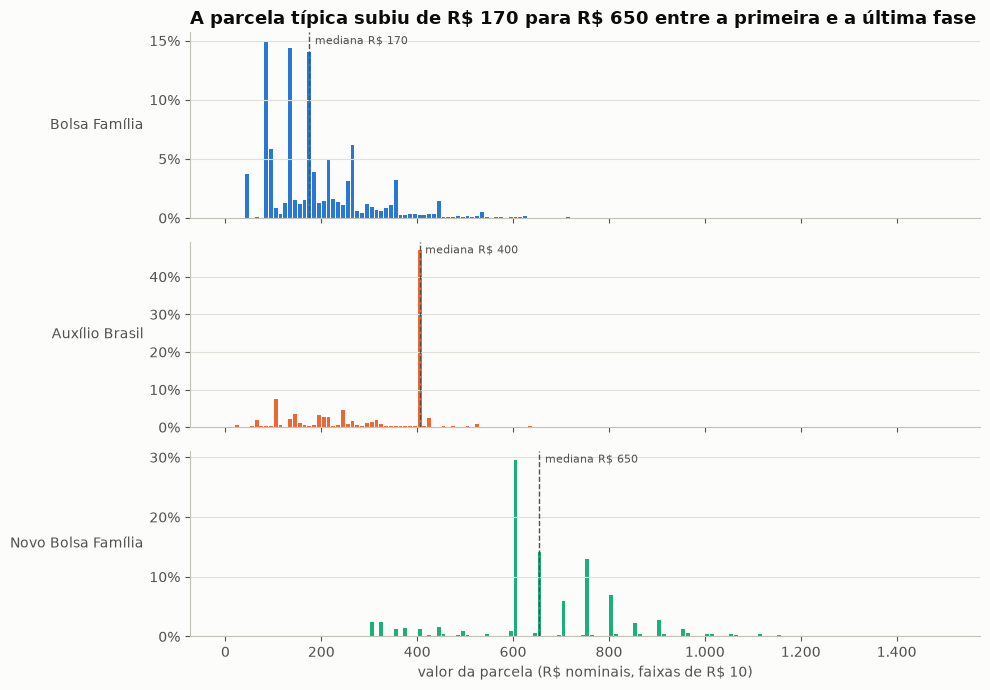

In [8]:
fx = faixas[faixas.mes_corrente].groupby(["fase", "faixa_inicio"], observed=True)[["linhas", "valor"]].sum().reset_index()


def quantil(g, qs):
    g = g.sort_values("faixa_inicio")
    acum = (g.linhas.cumsum() / g.linhas.sum()).to_numpy()
    return [g.faixa_inicio.iloc[min(np.searchsorted(acum, x), len(g) - 1)] for x in qs]


linhas_est = []
for f in FASES:
    g = fx[fx.fase == f]
    media = g.valor.sum() / g.linhas.sum()
    meio = g.faixa_inicio + 5
    desvio = np.sqrt((g.linhas * (meio - media) ** 2).sum() / g.linhas.sum())
    q1, q2, q3, p99 = quantil(g, [0.25, 0.5, 0.75, 0.99])
    iqr = q3 - q1
    sup, inf = q3 + 1.5 * iqr, q1 - 1.5 * iqr
    z3 = media + 3 * desvio
    linhas_est.append({"fase": f, "pagamentos": g.linhas.sum(), "média": media, "desvio": desvio, "Q1": q1,
                       "mediana": q2, "Q3": q3, "p99": p99,
                       "mín.": mensal[mensal.fase == f].valor_min.min(), "máx.": mensal[mensal.fase == f].valor_max.max(),
                       "cerca IQR sup.": sup, "% acima IQR": 100 * g[g.faixa_inicio >= sup].linhas.sum() / g.linhas.sum(),
                       "% abaixo IQR": 100 * g[g.faixa_inicio + 10 <= inf].linhas.sum() / g.linhas.sum(),
                       "média+3σ": z3, "% z>3": 100 * g[g.faixa_inicio >= z3].linhas.sum() / g.linhas.sum()})
est = pd.DataFrame(linhas_est).set_index("fase")
display(est.round(2))

fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, f in zip(axs, FASES):
    g = fx[(fx.fase == f) & (fx.faixa_inicio < 1500)]
    total = fx[fx.fase == f].linhas.sum()
    ax.bar(g.faixa_inicio + 5, 100 * g.linhas / total, width=8, color=COR[f])
    ax.axvline(est.loc[f, "mediana"] + 5, color=TINTA_2, lw=1, ls="--")
    ax.annotate(f"mediana R$ {br(est.loc[f, 'mediana'])}", (est.loc[f, "mediana"] + 5, 1),
                xycoords=("data", "axes fraction"), xytext=(4, -2), textcoords="offset points", va="top",
                fontsize=8, color=TINTA_2)
    ax.set_ylabel(f, rotation=0, ha="right", va="center", color=TINTA_2)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="x", visible=False)
axs[-1].set_xlabel("valor da parcela (R$ nominais, faixas de R$ 10)")
axs[-1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
axs[0].set_title(f"A parcela típica subiu de R$ {br(est.loc['Bolsa Família', 'mediana'])} para "
                 f"R$ {br(est.loc['Novo Bolsa Família', 'mediana'])} entre a primeira e a última fase")
plt.tight_layout()
plt.show()

As cercas do IQR e o z-score marcam como atípicos entre 0,4% e 11% dos pagamentos, conforme a fase e o critério, mas
esses valores não são erros, porque a parcela é calculada por regras (no Novo Bolsa Família, um valor por pessoa, um
piso por família e adicionais por criança, gestante e nutriz), então a distribuição tem vários picos e não segue uma
normal. Por exemplo, no Novo Bolsa Família as faixas mais comuns abaixo de R$ 375 são R$ 300, 320, 350 e 370 (7,5% das
parcelas), que são a metade das parcelas mais frequentes (R$ 600, 650, 700 e 750), o que bate com a regra de proteção,
em que a família cuja renda melhorou passa a receber 50% do benefício.

A decisão para a limpeza é não remover nenhum valor dentro da faixa plausível e só marcar os extremos (abaixo de
R$ 20 e a partir de R$ 3.000) e os retroativos, usando a mediana junto com a média nas agregações.

### 3.2 Categóricas: UF, município e NIS

In [9]:
card = mun.groupby(["fase", "periodo"], observed=True).agg(municipios=("cod_siafi", "nunique"), ufs=("uf", "nunique"))
card = card.join(mensal.set_index(["fase", "periodo"])[["familias"]])
display(card.groupby("fase", observed=True).agg(["min", "max"]))

por_uf = (mun.groupby(["uf", "fase"], observed=True).linhas.sum().unstack("fase"))
por_uf = (100 * por_uf / por_uf.sum()).round(2)
por_uf["Total (%)"] = (100 * mun.groupby("uf").linhas.sum() / mun.linhas.sum()).round(2)
display(por_uf.sort_values("Total (%)", ascending=False).T)

municipios       ufs      familias          
                          min   max min max       min       max
fase                                                           
Bolsa Família            5570  5570  27  27  13058225  14695093
Auxílio Brasil           5570  5570  27  27  14184631  21307538
Novo Bolsa Família       5570  5571  27  27  18013776  20801272

uf,BA,SP,PE,MG,RJ,CE,PA,MA,PB,PI,AM,RS,PR,AL,RN,GO,SE,ES,MT,SC,MS,TO,DF,AC,RO,AP,RR
fase,,,,,,,,,,,,,,,,,,,,,,,,,,,
Bolsa Família,12.95,11.14,8.28,7.56,6.47,7.58,6.80,6.80,3.67,3.20,2.86,2.63,2.69,2.87,2.54,2.14,2.03,1.35,1.13,0.89,0.90,0.84,0.57,0.64,0.57,0.54,0.35
Auxílio Brasil,12.42,11.98,8.09,7.78,7.93,7.27,6.28,5.90,3.40,3.03,2.78,2.81,2.82,2.66,2.46,2.29,1.94,1.45,1.20,1.00,0.97,0.78,0.70,0.62,0.58,0.55,0.31
Novo Bolsa Família,12.12,12.00,7.79,7.63,7.91,7.13,6.48,5.91,3.27,2.91,3.12,2.97,2.89,2.62,2.45,2.39,1.86,1.47,1.19,1.08,0.98,0.75,0.85,0.64,0.63,0.59,0.37
Total (%),12.42,11.74,7.99,7.63,7.48,7.29,6.54,6.18,3.41,3.02,2.98,2.84,2.82,2.70,2.48,2.30,1.93,1.43,1.17,1.01,0.95,0.78,0.74,0.64,0.60,0.57,0.36


Todos os 5.570 municípios (5.571 a partir de outubro de 2025) e as 27 UFs aparecem em todos os meses, e Bahia e São
Paulo concentram quase um quarto das linhas. A distribuição entre as UFs muda pouco de uma fase para outra, mas o
Sudeste ganhou peso, já que do Bolsa Família para o Novo Bolsa Família a participação do Rio de Janeiro subiu 1,4
ponto percentual e a de São Paulo 0,9, enquanto Maranhão (−0,9), Bahia (−0,8) e Pernambuco (−0,5) perderam, que é o
mesmo movimento das taxas por UF da seção 4.4.

## 4. Análise bivariada e temporal

### 4.1 Evolução mensal: famílias, valor total e valor por família

Aqui a família é o NIS distinto com algum pagamento no mês. Em novembro de 2021 os mesmos pagamentos aparecem nas duas
primeiras bases (ver a leitura abaixo), então a linha cinza conta cada família uma vez (tabela `transicoes`), e os
valores estão em reais nominais, sem correção pela inflação.

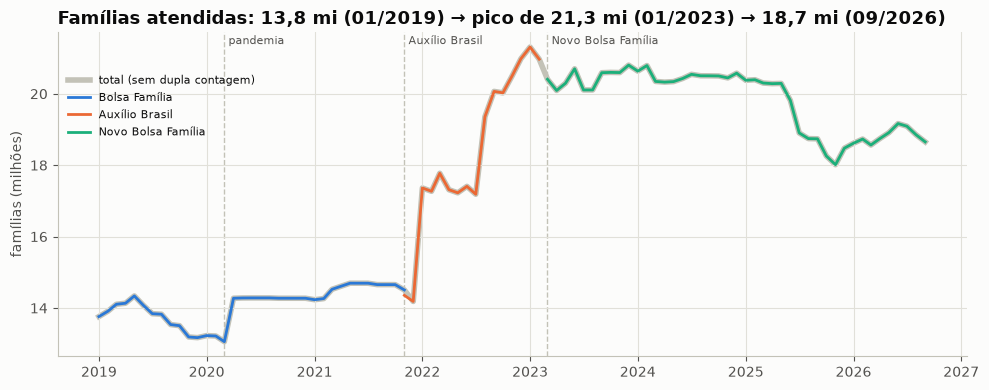

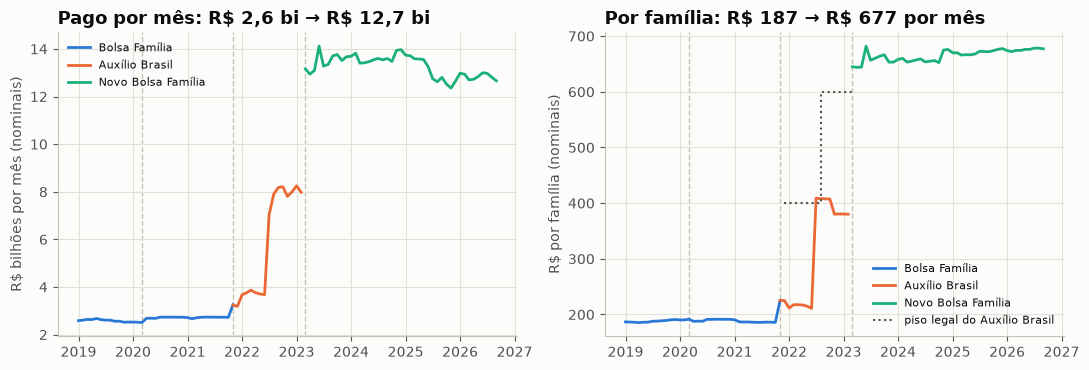

,periodo,fase,familias,valor_bi,r_por_familia,p05,p25,p50,p75,p95
49,202110,Bolsa Família,14654782,2.72,185.89,82.0,91.0,171.0,244.0,391.0
0,202111,Auxílio Brasil,14355279,3.23,225.12,100.0,149.0,201.0,296.0,471.0
50,202111,Bolsa Família,14506301,3.26,224.38,100.0,149.0,201.0,296.0,471.0
1,202112,Auxílio Brasil,14184631,3.19,224.98,100.0,149.0,201.0,296.0,472.0
2,202201,Auxílio Brasil,17361835,3.67,211.55,65.0,102.0,198.0,284.0,442.0
3,202202,Auxílio Brasil,17268904,3.76,217.65,65.0,110.0,198.0,295.0,451.0
4,202203,Auxílio Brasil,17773180,3.87,217.59,65.0,106.0,198.0,295.0,457.0
5,202204,Auxílio Brasil,17313174,3.76,217.19,65.0,106.0,198.0,295.0,458.0
6,202205,Auxílio Brasil,17226355,3.71,214.91,65.0,106.0,198.0,293.0,451.0
7,202206,Auxílio Brasil,17406634,3.68,211.02,65.0,106.0,195.0,283.0,447.0


In [10]:
uniao = trans[["periodo", "data", "familias_atual"]].rename(columns={"familias_atual": "familias"})
primeiro = mensal.sort_values("periodo").iloc[0]
uniao = pd.concat([pd.DataFrame({"periodo": [primeiro.periodo], "data": [primeiro.data],
                                 "familias": [primeiro.familias]}), uniao]).sort_values("data")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(uniao.data, uniao.familias / 1e6, color=EIXO, lw=4, zorder=1, label="total (sem dupla contagem)")
for f in FASES:
    s = mensal[mensal.fase == f].sort_values("data")
    ax.plot(s.data, s.familias / 1e6, color=COR[f], label=f, zorder=2)
marcar_transicoes(ax)
ax.set_ylabel("famílias (milhões)")
ini, fim, pico = uniao.iloc[0], uniao.iloc[-1], uniao.loc[uniao.familias.idxmax()]
ax.set_title(f"Famílias atendidas: {mi(ini.familias)} ({ini.periodo[4:]}/{ini.periodo[:4]}) → pico de "
             f"{mi(pico.familias)} ({pico.periodo[4:]}/{pico.periodo[:4]}) → {mi(fim.familias)} "
             f"({fim.periodo[4:]}/{fim.periodo[:4]})")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9), fontsize=8)
plt.tight_layout()
plt.show()

serie = mensal.groupby(["data", "fase"], observed=True)[["valor_total", "valor_mes_corrente",
                                                          "familias_mes_corrente"]].sum().reset_index()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for f in FASES:
    s = serie[serie.fase == f]
    axs[0].plot(s.data, s.valor_total / 1e9, color=COR[f], label=f)
    axs[1].plot(s.data, s.valor_mes_corrente / s.familias_mes_corrente, color=COR[f], label=f)
for ax in axs:
    marcar_transicoes(ax, rotulos=False)
axs[0].set_ylabel("R$ bilhões por mês (nominais)")
tot = serie.groupby("data").valor_total.sum()
axs[0].set_title(f"Pago por mês: R$ {br(tot.iloc[0] / 1e9, 1)} bi → R$ {br(tot.iloc[-1] / 1e9, 1)} bi")
axs[1].set_ylabel("R$ por família (nominais)")
# piso garantido por família no Auxílio Brasil: R$ 400 (dez/2021 a jul/2022) e R$ 600 (ago/2022 a fev/2023)
piso = pd.DataFrame({"data": pd.to_datetime(["2021-12-01", "2022-08-01", "2023-03-01"]), "piso": [400, 600, 600]})
axs[1].step(piso.data, piso.piso, where="post", color=TINTA_2, lw=1.5, ls=":", label="piso legal do Auxílio Brasil")
axs[1].legend(loc="lower right", fontsize=8)
vpm = (serie.groupby("data").valor_mes_corrente.sum() / serie.groupby("data").familias_mes_corrente.sum())
axs[1].set_title(f"Por família: R$ {br(vpm.iloc[0])} → R$ {br(vpm.iloc[-1])} por mês")
axs[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# zoom nas transições: valor por família e quantis da parcela, mês a mês
zoom = mensal[mensal.periodo.between("202110", "202304")].sort_values(["periodo", "base"])
zoom = zoom.assign(valor_bi=zoom.valor_total / 1e9,
                   r_por_familia=zoom.valor_mes_corrente / zoom.familias_mes_corrente)
display(zoom[["periodo", "fase", "familias", "valor_bi", "r_por_familia", "p05", "p25", "p50", "p75", "p95"]].round(2))

O número de famílias foi de 13,8 milhões em janeiro de 2019 ao pico de 21,3 milhões em janeiro de 2023 e depois a
18,7 milhões em setembro de 2026, e o valor pago por mês subiu de R$ 2,6 bilhões para R$ 12,7 bilhões, com o valor por
família indo de R$ 187 para R$ 677 (sem correção pela inflação).

Essa seção mostrou dois problemas que mudam o tratamento dos dados. O primeiro é que novembro de 2021 está nas duas
bases, porque o arquivo do Bolsa Família tem os mesmos quantis de valor que o do Auxílio Brasil (mediana de R$ 201 nos
dois), quase o mesmo total (R$ 3,26 bilhões contra R$ 3,23 bilhões) e todas as 14.355.279 famílias do Auxílio Brasil,
com 151 mil a mais, então somar as bases dobraria o mês, e por isso nas contas por município da seção 4.4 fica a base
com mais famílias e na limpeza o mês é deduplicado por NIS e mês de referência.

O segundo é que o Auxílio Brasil aparece abaixo do piso legal, porque de dezembro de 2021 a junho de 2022 a família
recebe em média de R$ 211 a R$ 225 (mediana de R$ 195 a R$ 201), quando a regra da época previa R$ 400 (linha
pontilhada no gráfico), e de agosto de 2022 a fevereiro de 2023 a média fica entre R$ 380 e R$ 408, quando o piso era
R$ 600. O mais provável é que essa base tenha só uma parte da transferência e que o benefício extraordinário, criado
para completar o piso, esteja fora dela, então antes de comparar valores entre as fases (pergunta 2) é preciso
conferir com outra fonte, como os totais mensais do MDS.

### 4.2 Entradas e saídas de famílias mês a mês

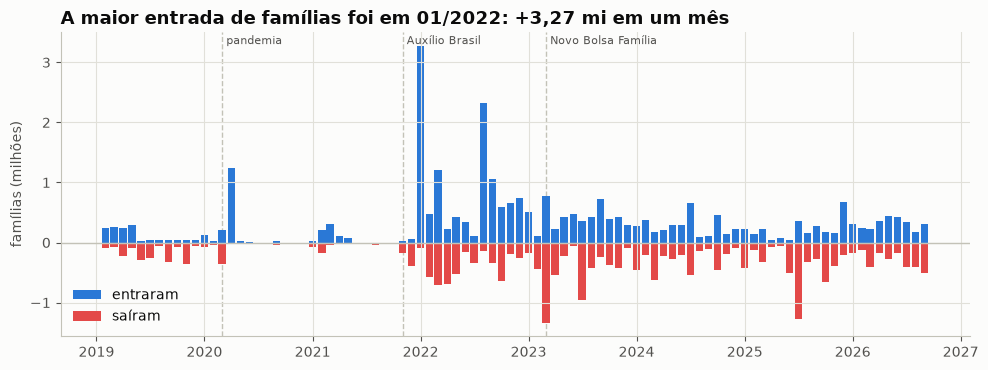

,periodo_anterior,periodo,bases_anterior,bases_atual,familias_anterior,familias_atual,familias_em_duas_bases,permaneceram,entraram,sairam
32,202109,202110,bolsa_familia_pagamentos,bolsa_familia_pagamentos,14655263,14654782,0,14654780,2,483
33,202110,202111,bolsa_familia_pagamentos,auxilio_brasil+bolsa_familia_pagamentos,14654782,14506301,14355279,14474083,32218,180699
34,202111,202112,auxilio_brasil+bolsa_familia_pagamentos,auxilio_brasil,14506301,14184631,0,14123435,61196,382866
48,202301,202302,auxilio_brasil,auxilio_brasil,21307538,20967506,0,20864355,103151,443183
49,202302,202303,auxilio_brasil,novo_bolsa_familia,20967506,20406579,0,19634824,771755,1332682
50,202303,202304,novo_bolsa_familia,novo_bolsa_familia,20406579,20091550,0,19869420,222130,537159


In [11]:
t = trans.sort_values("data")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(t.data, t.entraram / 1e6, width=25, color=POSITIVO, label="entraram")
ax.bar(t.data, -t.sairam / 1e6, width=25, color=NEGATIVO, label="saíram")
marcar_transicoes(ax)
ax.axhline(0, color=EIXO, lw=1)
ax.set_ylabel("famílias (milhões)")
maior = t.loc[t.entraram.idxmax()]
ax.set_title(f"A maior entrada de famílias foi em {maior.periodo[4:]}/{maior.periodo[:4]}: "
             f"+{mi(maior.entraram, 2)} em um mês")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
display(t[t.periodo.isin(["202110", "202111", "202112", "202302", "202303", "202304"])][
    ["periodo_anterior", "periodo", "bases_anterior", "bases_atual", "familias_anterior", "familias_atual",
     "familias_em_duas_bases", "permaneceram", "entraram", "sairam"]])

O fluxo de famílias acompanha as decisões de política. Em abril de 2020, no começo da pandemia, entraram 1,24 milhão
de famílias, e de maio a dezembro de 2020 o cadastro ficou praticamente congelado, com cerca de 6 mil entradas e 6 mil
saídas por mês, contra 120 mil e 173 mil por mês em 2019. Na expansão do Auxílio Brasil entraram 3,27 milhões de
famílias em janeiro de 2022 e 2,32 milhões em agosto de 2022, e na transição para o Novo Bolsa Família (março de 2023)
saíram 1,33 milhão e entraram 0,77 milhão.

Em julho de 2025 saíram 1,27 milhão de famílias, e a causa (mudança de regra ou revisão do cadastro) fica para
investigar. Desde 2024 saem em média 327 mil famílias por mês e entram 262 mil, então a redução é contínua.

### 4.3 Defasagem entre o mês pago e o mês de referência (pagamentos retroativos)

In [12]:
d = defas.copy()
d["atraso"] = d.meses_de_atraso.clip(upper=13).map(lambda m: "13+" if m >= 13 else str(int(m)))
ret = d.groupby("fase", observed=True).apply(lambda g: pd.Series({
    "% linhas retroativas": 100 * g[g.meses_de_atraso > 0].linhas.sum() / g.linhas.sum(),
    "% valor retroativo": 100 * g[g.meses_de_atraso > 0].valor.sum() / g.valor.sum(),
    "atraso máx. (meses)": g.meses_de_atraso.max(),
    "linhas com referência futura": g[g.meses_de_atraso < 0].linhas.sum()}), include_groups=False)
display(ret.round(2))
dist = d[d.meses_de_atraso > 0].groupby(["atraso", "fase"], observed=True).linhas.sum().unstack("fase")
dist = dist.reindex([str(i) for i in range(1, 13)] + ["13+"])
display((100 * dist / dist.sum()).round(1))

,% linhas retroativas,% valor retroativo,atraso máx. (meses),linhas com referência futura
fase,,,,
Bolsa Família,0.22,0.16,12.0,0.0
Auxílio Brasil,0.22,0.25,18.0,0.0
Novo Bolsa Família,0.76,0.70,17.0,0.0


fase,Bolsa Família,Auxílio Brasil,Novo Bolsa Família
atraso,,,
1,41.0,63.6,27.4
2,25.1,18.8,25.3
3,15.3,12.9,20.4
4,10.2,1.9,13.5
5,7.3,1.4,7.6
6,0.3,1.4,4.7
7,0.2,0.0,1.0
8,0.2,0.0,0.1
9,0.1,0.0,0.1


Os pagamentos retroativos são poucos, 0,22% das linhas no Bolsa Família e no Auxílio Brasil e 0,76% no Novo Bolsa
Família, e de 94% a 99% deles têm de 1 a 5 meses de atraso, com máximo de 18. No Auxílio Brasil parte dos retroativos
se refere a meses do Bolsa Família (por exemplo, setembro e outubro de 2021 pagos em março de 2022). Mesmo assim uma
família com parcela atrasada aparece em mais de uma linha no mês, então as contagens usam NIS distintos, o valor do
mês considera só a parcela corrente e a gold guarda o valor retroativo numa coluna separada.

### 4.4 Cobertura por UF e região: famílias por 100 mil habitantes (integração com o IBGE)

A população municipal vem das estimativas anuais do IBGE (2019 a 2021 e 2024 a 2026), que não existem para 2022 e
2023. O Censo 2022 é a população contada e fica cerca de 5% abaixo das estimativas, tanto as de antes quanto as de
depois dele (tabela abaixo), então usado como denominador ele criaria um salto falso na taxa de 2022. Por isso 2022 e
2023 são interpolados em linha reta entre as estimativas de 2021 e 2024, município a município, o Censo fica só como
conferência e as famílias de cada ano são a média mensal do ano.

Municípios com população por ano: {2019: 5570, 2020: 5570, 2021: 5570, 2022: 5570, 2023: 5570, 2024: 5570, 2025: 5571, 2026: 5571}


,estimativa IBGE,Censo 2022 (contagem),interpolada (usada aqui)
ano,,,
2019,210.15,,
2020,211.76,,
2021,213.32,,
2022,,203.08,213.07
2023,,,212.83
2024,212.58,,
2025,213.42,,
2026,214.21,,


O Censo 2022 fica 4,7% abaixo da população interpolada para 2022: usado como denominador, inflaria a taxa de 2022 em 4,9%.


Município × ano sem população: 0 de 44562


ano                       2019     2020     2021     2022     2023     2024     2025     2026
regiao       sigla_uf                                                                        
Centro-Oeste DF         2332.0   2617.0   2891.0   4235.0   5781.0   6064.0   5285.0   5234.0
             GO         4201.0   4214.0   4331.0   5890.0   6715.0   6821.0   6170.0   5905.0
             MS         4417.0   4499.0   4672.0   6317.0   7059.0   7062.0   6415.0   6209.0
             MT         4392.0   4460.0   4648.0   6129.0   6693.0   6590.0   5814.0   5325.0
Nordeste     AL        12029.0  11988.0  12262.0  14803.0  16270.0  16442.0  15851.0  15528.0
             BA        12175.0  12154.0  12378.0  15418.0  16609.0  16429.0  15958.0  15717.0
             CE        11468.0  11603.0  11848.0  14584.0  15829.0  15685.0  15005.0  14521.0
             MA        13568.0  13391.0  13491.0  15294.0  16182.0  17177.0  16833.0  16385.0
             PB        12835.0  12744.0  12830.0  15377.0  16361.0  15994.0  15373.0  14848.0
             PE        12147.0  12079.0  12233.0  15575.0  17028.0  16422.0  15843.0  15428.0
             PI        13725.0  13680.0  13899.0  16912.0  17958.0  17547.0  16808.0  16028.0
             RN        10013.0  10098.0  10302.0  12976.0  14334.0  14370.0  13810.0  13475.0
             SE        12524.0  12270.0  12243.0  15491.0  16741.0  16406.0  15822.0  15448.0
Norte        AC        10143.0  10024.0   9992.0  12831.0  14272.0  14774.0  14340.0  13973.0
             AM         9683.0   9598.0   9487.0  11940.0  14218.0  15027.0  14398.0  13839.0
             AP         9144.0   8836.0   8623.0  12063.0  14300.0  14738.0  14520.0  13918.0
             PA        11160.0  10987.0  10948.0  13263.0  14493.0  15383.0  14753.0  14335.0
             RO         4355.0   4467.0   4612.0   5975.0   6897.0   7294.0   7277.0   7033.0
             RR         7828.0   7950.0   7871.0   8539.0   9606.0  10544.0  10294.0   9766.0
             TO         7397.0   7341.0   7523.0   9092.0   9700.0   9893.0   9267.0   8807.0
Sudeste      ES         4421.0   4668.0   4947.0   6591.0   7256.0   7324.0   6941.0   6636.0
             MG         4826.0   4946.0   5243.0   6772.0   7416.0   7360.0   6860.0   6623.0
             RJ         4983.0   5235.0   5540.0   8461.0  10150.0   9508.0   8546.0   8120.0
             SP         3272.0   3340.0   3574.0   4791.0   5465.0   5383.0   4912.0   4794.0
Sul          PR         3160.0   3242.0   3491.0   4499.0   4994.0   5077.0   4699.0   4561.0
             RS         3073.0   3217.0   3464.0   4567.0   5304.0   5777.0   5111.0   4646.0
             SC         1613.0   1723.0   1883.0   2451.0   2807.0   2797.0   2526.0   2433.0

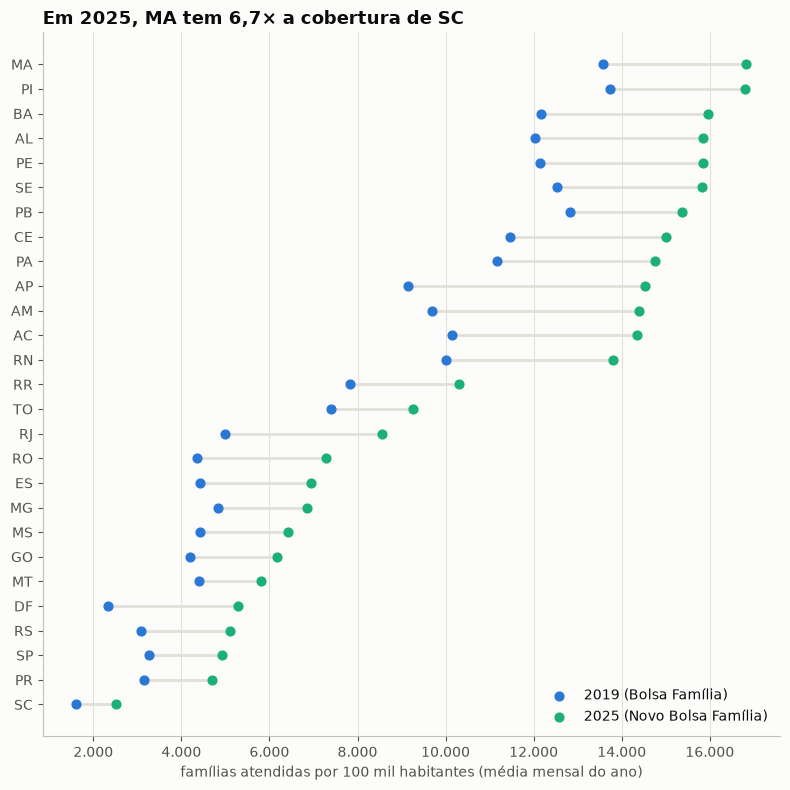

Desigualdade entre UFs (coeficiente de variação da taxa): {2019: np.float64(0.515), 2020: np.float64(0.501), 2021: np.float64(0.487), 2022: np.float64(0.455), 2023: np.float64(0.433), 2024: np.float64(0.427), 2025: np.float64(0.447), 2026: np.float64(0.453)}


ano,2019,2020,2021,2022,2023,2024,2025,2026
regiao,,,,,,,,
Centro-Oeste,3933.0,4019.0,4190.0,5714.0,6602.0,6678.0,5978.0,5708.0
Nordeste,12238.0,12204.0,12385.0,15196.0,16409.0,16309.0,15758.0,15355.0
Norte,9600.0,9488.0,9459.0,11671.0,13108.0,13838.0,13307.0,12858.0
Sudeste,4031.0,4154.0,4419.0,6063.0,6927.0,6750.0,6180.0,5965.0
Sul,2757.0,2868.0,3093.0,4018.0,4554.0,4739.0,4279.0,4030.0


In [13]:
est_pop = sql(f"""
    SELECT TRY_CAST("Município (Código)" AS INTEGER) AS cod_ibge, TRY_CAST("Ano" AS INTEGER) AS ano,
           TRY_CAST("Valor" AS BIGINT) AS populacao
    FROM read_parquet('{(REF / "ibge_estimativas_populacao_municipios" / "*" / "*.parquet").as_posix()}',
                      hive_partitioning = false)""")
censo = sql(f"""
    SELECT TRY_CAST("Município (Código)" AS INTEGER) AS cod_ibge, 2022 AS ano, TRY_CAST("Valor" AS BIGINT) AS populacao
    FROM read_parquet('{(REF / "ibge_censo2022_populacao_municipios" / "populacao.parquet").as_posix()}')""")
est = est_pop[est_pop.ano >= 2019].dropna()
larga = est.pivot_table(index="cod_ibge", columns="ano", values="populacao")
interp = pd.concat([
    (larga[2021] + (larga[2024] - larga[2021]) * k / 3).round().rename("populacao").reset_index().assign(ano=2021 + k)
    for k in (1, 2)]).dropna()
pop = pd.concat([est, interp])
print("Municípios com população por ano:", pop.groupby("ano").cod_ibge.nunique().to_dict())
fontes_pop = pd.DataFrame({"estimativa IBGE": est.groupby("ano").populacao.sum(),
                           "Censo 2022 (contagem)": censo.groupby("ano").populacao.sum(),
                           "interpolada (usada aqui)": interp.groupby("ano").populacao.sum()}) / 1e6
display(fontes_pop.astype(float).round(2).astype(object).fillna(""))
c22 = censo.populacao.sum() / interp[interp.ano == 2022].populacao.sum() - 1
print(f"O Censo 2022 fica {pct(-c22)} abaixo da população interpolada para 2022: usado como denominador, inflaria a "
      f"taxa de 2022 em {pct(1 / (1 + c22) - 1)}.")

mm = mun.merge(ref[["cod_siafi", "cod_ibge", "sigla_uf", "sigla_regiao", "regiao"]], on="cod_siafi", how="left")
# famílias e valor por município e mês. Em nov/2021 o arquivo do Bolsa Família repete os pagamentos do Auxílio
# Brasil (seção 4.1): somar as duas bases contaria duas vezes. Fica a base com mais famílias no município, com a
# linha inteira (para não juntar famílias de uma base com o valor da outra). Nos demais meses só há uma base.
mes_mun = mm.groupby(["cod_ibge", "sigla_uf", "regiao", "ano", "periodo", "base"], observed=True)[
    ["familias", "valor_mes_corrente", "familias_mes_corrente", "linhas", "linhas_retroativas",
     "linhas_cpf_ausente"]].sum().reset_index()
mes_mun = (mes_mun.sort_values("familias", ascending=False)
           .drop_duplicates(["cod_ibge", "periodo"]).drop(columns="base"))
anual = mes_mun.groupby(["cod_ibge", "sigla_uf", "regiao", "ano"], observed=True).agg(
    familias=("familias", "mean"), valor=("valor_mes_corrente", "sum"), fam_corr=("familias_mes_corrente", "sum"),
    linhas=("linhas", "sum"), retro=("linhas_retroativas", "sum"), sem_cpf=("linhas_cpf_ausente", "sum")).reset_index()
anual = anual.merge(pop, on=["cod_ibge", "ano"], how="left")
sem_pop = anual[anual.populacao.isna()]
print(f"Município × ano sem população: {len(sem_pop)} de {len(anual)}")
anual["taxa"] = 1e5 * anual.familias / anual.populacao
anual["valor_por_familia"] = anual.valor / anual.fam_corr

uf = anual.groupby(["sigla_uf", "regiao", "ano"], observed=True)[["familias", "populacao"]].sum().reset_index()
uf["taxa"] = 1e5 * uf.familias / uf.populacao
tab_uf = uf.pivot_table(index=["regiao", "sigla_uf"], columns="ano", values="taxa").round(0)
display(tab_uf)

a0, a1 = 2019, 2025
u = uf.pivot_table(index="sigla_uf", columns="ano", values="taxa")[[a0, a1]].sort_values(a1)
fig, ax = plt.subplots(figsize=(8, 8))
y = np.arange(len(u))
ax.hlines(y, u[a0], u[a1], color=GRADE, lw=2, zorder=1)
ax.scatter(u[a0], y, s=40, color=COR["Bolsa Família"], label=f"{a0} (Bolsa Família)", zorder=2)
ax.scatter(u[a1], y, s=40, color=COR["Novo Bolsa Família"], label=f"{a1} (Novo Bolsa Família)", zorder=3)
ax.set_yticks(y, u.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("famílias atendidas por 100 mil habitantes (média mensal do ano)")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
ax.set_title(f"Em {a1}, {u.index[-1]} tem {br(u[a1].iloc[-1] / u[a1].iloc[0], 1)}× a cobertura de {u.index[0]}")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

cv = uf.groupby("ano").taxa.agg(lambda s: s.std() / s.mean())
print("Desigualdade entre UFs (coeficiente de variação da taxa):", {k: round(v, 3) for k, v in cv.items()})
reg = anual.groupby(["regiao", "ano"], observed=True)[["familias", "populacao"]].sum()
display((1e5 * reg.familias / reg.populacao).unstack("ano").round(0))

A cobertura varia muito mais entre as regiões do que no tempo. Em 2025 o Nordeste tem 15,8 mil famílias por 100 mil
habitantes e o Sul 4,3 mil, e o Maranhão tem 6,7 vezes a cobertura de Santa Catarina. Todas as UFs ampliaram a
cobertura de 2019 até 2023 e 2024 e recuaram um pouco depois, com o Rio de Janeiro dobrando (de 5,0 mil em 2019 para
10,2 mil em 2023) e caindo para 8,1 mil em 2026, e a desigualdade entre as UFs, medida pelo coeficiente de variação,
caiu de 0,52 em 2019 para 0,43 em 2024 e voltou a 0,45 em 2025 e 2026.

Com o Censo 2022 como denominador, a taxa de 2022 sairia 4,9% maior só pela troca de fonte, e 2023 teria metade desse
efeito, criando um pico falso na série. Com a interpolação, 2023 (9.654) e 2024 (9.641) ficam praticamente empatados
no topo.

### 4.5 Relação entre variáveis no nível do município

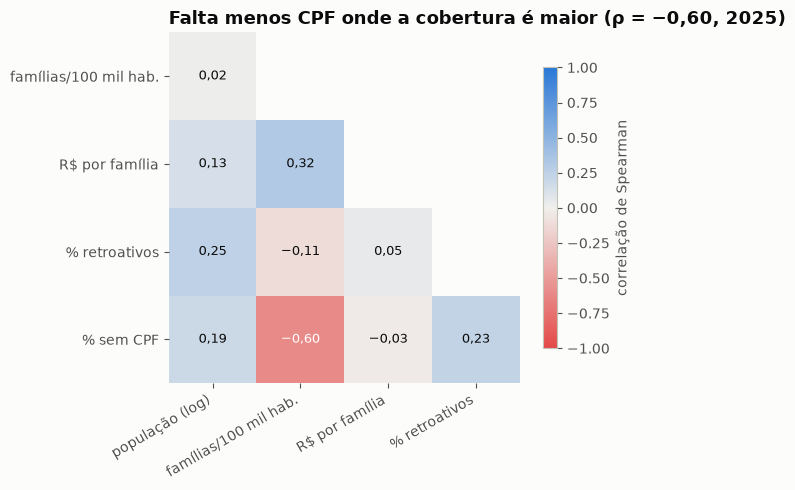

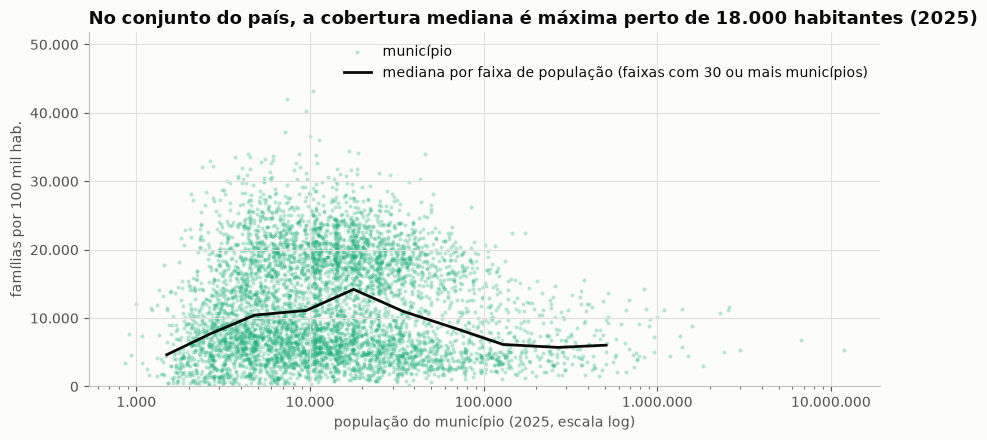

Municípios com mais de 30 mil famílias por 100 mil hab. em 2025: 52


,nome_ibge,sigla_uf,populacao,familias,taxa
647,Serrano do Maranhão,MA,10475.0,4520.0,43146.0
1801,Pedrinhas,SE,7355.0,3090.0,42019.0
2119,Pau Brasil,BA,9537.0,3843.0,40296.0
503,Central do Maranhão,MA,7220.0,2682.0,37145.0
492,Cachoeira Grande,MA,10032.0,3669.0,36569.0
590,Peri Mirim,MA,11229.0,4046.0,36029.0
494,Cajari,MA,16680.0,5735.0,34382.0
628,São João Batista,MA,18889.0,6452.0,34160.0


,municipios,taxa_mediana,valor_por_familia_mediano
porte,,,
< 5 mil,1285,8390.0,660.0
5–10 mil,1184,10765.0,664.0
10–20 mil,1350,13562.0,668.0
20–50 mil,1070,12424.0,668.0
50–100 mil,344,8509.0,665.0
100–500 mil,290,6006.0,663.0
> 500 mil,48,6351.0,660.0


Taxa mediana: até 100 mil hab. = 10.507; 100 mil ou mais = 6.013
Municípios de cada porte, por região (% da coluna):


porte,< 5 mil,5–10 mil,10–20 mil,20–50 mil,50–100 mil,100–500 mil,> 500 mil
regiao,,,,,,,
Centro-Oeste,11.2,8.4,7.0,7.8,5.8,7.6,10.4
Nordeste,18.2,31.2,43.4,39.2,33.7,20.0,22.9
Norte,6.8,5.8,7.5,11.2,12.5,8.6,8.3
Sudeste,30.3,32.0,26.1,27.0,29.9,45.9,47.9
Sul,33.5,22.6,16.0,14.9,18.0,17.9,10.4


Taxa mediana por região e porte (famílias por 100 mil hab.):


porte,< 5 mil,5–10 mil,10–20 mil,20–50 mil,50–100 mil,100–500 mil,> 500 mil
regiao,,,,,,,
Centro-Oeste,9134.0,8054.0,7537.0,6132.0,5983.0,4835.0,4977.0
Nordeste,20679.0,20813.0,19911.0,18745.0,16715.0,12240.0,10141.0
Norte,12507.0,13689.0,16944.0,18143.0,15613.0,11315.0,10188.0
Sudeste,8236.0,8560.0,6834.0,6416.0,4934.0,4725.0,5091.0
Sul,4249.0,4497.0,4866.0,3761.0,3693.0,4337.0,3068.0


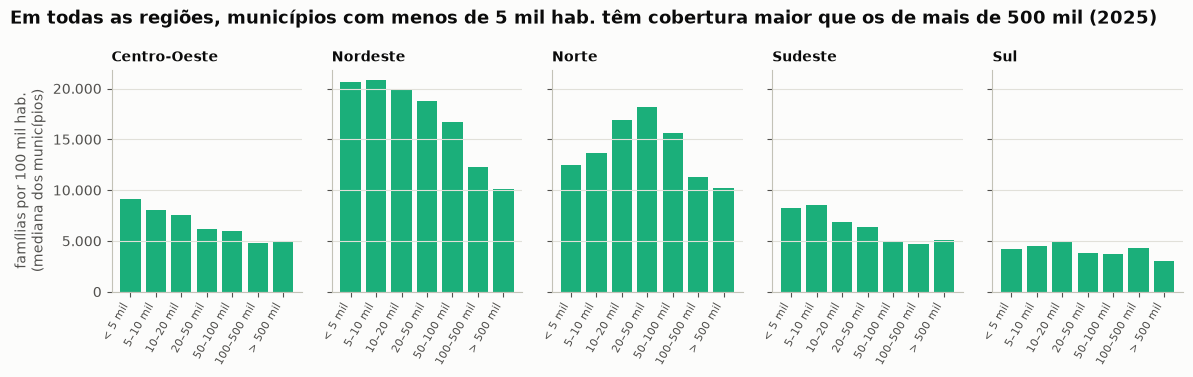

In [14]:
ANO = 2025
m = anual[(anual.ano == ANO) & anual.populacao.notna()].copy()
m["log10_pop"] = np.log10(m["populacao"])
m["% retroativos"] = 100 * m.retro / m.linhas
m["% sem CPF"] = 100 * m.sem_cpf / m.linhas
vars_ = {"log10_pop": "população (log)", "taxa": "famílias/100 mil hab.", "valor_por_familia": "R$ por família",
         "% retroativos": "% retroativos", "% sem CPF": "% sem CPF"}
corr = m[list(vars_)].rename(columns=vars_).corr(method="spearman")
sub = corr.iloc[1:, :-1]  # sem a diagonal e sem o triângulo de cima, que repete o de baixo
sub = sub.where(~np.triu(np.ones(sub.shape, dtype=bool), k=1))
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(sub, cmap=DIVERGENTE, vmin=-1, vmax=1)
ax.set_xticks(range(sub.shape[1]), sub.columns, rotation=30, ha="right")
ax.set_yticks(range(sub.shape[0]), sub.index)
ax.grid(False)
for lado in ax.spines.values():
    lado.set_visible(False)
for i in range(sub.shape[0]):
    for k in range(i + 1):
        v = sub.iloc[i, k]
        ax.text(k, i, br(v, 2), ha="center", va="center", fontsize=9, color=TINTA if abs(v) < 0.6 else "#ffffff")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlação de Spearman")
rho = corr.loc["população (log)", "famílias/100 mil hab."]
rho_cpf = corr.loc["% sem CPF", "famílias/100 mil hab."]
ax.set_title(f"Falta menos CPF onde a cobertura é maior (ρ = {br(rho_cpf, 2)}, {ANO})" if rho_cpf < 0 else
             f"Falta mais CPF onde a cobertura é maior (ρ = {br(rho_cpf, 2)}, {ANO})")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(m["populacao"], m.taxa, s=8, alpha=0.3, color=COR["Novo Bolsa Família"], linewidths=0, label="município")
cortes = np.logspace(np.log10(m["populacao"].min()), np.log10(m["populacao"].max()), 15)
m["faixa_pop"] = pd.cut(m["populacao"], cortes, include_lowest=True)
med = m.groupby("faixa_pop", observed=True).agg(x=("populacao", "median"), y=("taxa", "median"), n=("taxa", "size"))
med = med[med.n >= 30]  # faixas com poucos municípios deixam a mediana instável
ax.plot(med.x, med.y, color=TINTA, lw=2, label="mediana por faixa de população (faixas com 30 ou mais municípios)")
ax.set_xscale("log")
ax.set_ylim(0, m.taxa.max() * 1.2)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
ax.set_xlabel(f"população do município ({ANO}, escala log)")
ax.set_ylabel("famílias por 100 mil hab.")
pico = med.loc[med.y.idxmax()]
ax.set_title(f"No conjunto do país, a cobertura mediana é máxima perto de {br(round(pico.x, -3))} habitantes ({ANO})")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

ext = m.merge(ref[["cod_ibge", "nome_ibge"]].drop_duplicates("cod_ibge"), on="cod_ibge", how="left")
print(f"Municípios com mais de 30 mil famílias por 100 mil hab. em {ANO}: {(m.taxa > 30_000).sum()}")
display(ext.nlargest(8, "taxa")[["nome_ibge", "sigla_uf", "populacao", "familias", "taxa"]].round(0))

PORTES = [0, 5_000, 10_000, 20_000, 50_000, 100_000, 500_000, np.inf]
ROT = ["< 5 mil", "5–10 mil", "10–20 mil", "20–50 mil", "50–100 mil", "100–500 mil", "> 500 mil"]
m["porte"] = pd.cut(m["populacao"], PORTES, labels=ROT, right=False)
display(m.groupby("porte", observed=True).agg(municipios=("cod_ibge", "count"), taxa_mediana=("taxa", "median"),
                                               valor_por_familia_mediano=("valor_por_familia", "median")).round(0))
print(f"Taxa mediana: até 100 mil hab. = {br(m[m.populacao < 100_000].taxa.median())}; "
      f"100 mil ou mais = {br(m[m.populacao >= 100_000].taxa.median())}")

# o porte se mistura com a região: onde estão os municípios de cada porte, e a taxa por porte dentro de cada região
qtd = pd.crosstab(m.regiao, m.porte)
print("Municípios de cada porte, por região (% da coluna):")
display((100 * qtd / qtd.sum()).round(1))
rp = m.groupby(["regiao", "porte"], observed=True).taxa.median().unstack().reindex(columns=ROT)
print("Taxa mediana por região e porte (famílias por 100 mil hab.):")
display(rp.round(0))
regioes = list(rp.index)
fig, axs = plt.subplots(1, len(regioes), figsize=(12, 3.8), sharey=True)
for ax, r in zip(axs, regioes):
    ax.bar(range(len(ROT)), rp.loc[r].values, width=0.8, color=COR["Novo Bolsa Família"])
    ax.set_xticks(range(len(ROT)), ROT, rotation=60, ha="right", fontsize=8)
    ax.set_title(r, fontsize=10)
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("famílias por 100 mil hab.\n(mediana dos municípios)")
axs[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: br(v)))
n_ok = int(sum(rp.loc[r].iloc[0] > rp.loc[r].iloc[-1] for r in regioes))
quem = "Em todas as regiões" if n_ok == len(regioes) else f"Em {n_ok} das {len(regioes)} regiões"
fig.suptitle(f"{quem}, municípios com menos de 5 mil hab. têm cobertura maior que os de mais de 500 mil ({ANO})",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

No conjunto do país o porte quase não se relaciona com a cobertura (Spearman ρ = 0,02) e a curva tem forma de U
invertido, com pico perto de 18 mil habitantes, mas essa forma vem em boa parte da mistura de regiões. Três quartos
dos municípios com menos de 5 mil habitantes ficam no Sul, no Sudeste e no Centro-Oeste, onde a cobertura é mais
baixa, enquanto 43% dos municípios de 10 a 20 mil habitantes estão no Nordeste, e isso puxa para baixo a mediana
nacional dos muito pequenos.

Dentro de cada região, os municípios com menos de 5 mil habitantes têm cobertura maior que os de mais de 500 mil nas
cinco regiões. No Nordeste, no Sudeste e no Centro-Oeste a taxa cai quase sempre com o porte (no Nordeste, de 20,7 mil
para 10,1 mil por 100 mil habitantes), no Norte o pico fica entre 20 e 50 mil habitantes e no Sul a taxa é baixa em
todos os portes, lembrando que acima de 500 mil habitantes as medianas do Centro-Oeste, do Norte e do Sul vêm de 4 ou
5 cidades.

O valor por família fica quase igual entre os portes (de R$ 660 a R$ 668), como se espera de uma regra nacional, e a
correlação mais forte do quadro é de qualidade e não de política, porque a falta de CPF é maior onde a cobertura é
menor (ρ = −0,60). Por fim, 52 municípios têm mais de 30 mil famílias por 100 mil habitantes (o maior é Serrano do
Maranhão, com 43 mil), o que com famílias de duas ou três pessoas passa de metade da população, então são números
plausíveis para municípios pobres do Maranhão e de outros estados do Nordeste, mas que pedem conferência da população
estimada.

## 5. Respostas preliminares às 5 perguntas

In [15]:
def taxa_br(ano):
    a = anual[(anual.ano == ano) & anual.populacao.notna()]
    return 1e5 * a.familias.sum() / a["populacao"].sum()


print("1) Famílias por 100 mil habitantes (Brasil, média mensal):",
      {a: br(taxa_br(a)) for a in sorted(anual.ano.unique())})
vpf = serie.groupby("fase", observed=True).apply(
    lambda g: g.valor_mes_corrente.sum() / g.familias_mes_corrente.sum(), include_groups=False)
print("2) Valor médio por família, por fase (R$):", {k: br(v, 2) for k, v in vpf.items()})
print("3) Coeficiente de variação da taxa entre UFs:", {k: br(v, 3) for k, v in cv.items()})
print(f"4) Correlação de Spearman entre população (log) e taxa em {ANO}: {br(rho, 2)}; regiões em que os municípios "
      f"com menos de 5 mil hab. têm taxa maior que os de mais de 500 mil: {n_ok} de {len(regioes)}")
w = anual.pivot_table(index=["cod_ibge", "regiao"], columns="ano", values="taxa").reset_index()
w["cresc_19_22"] = w[2022] - w[2019]
w["var_22_25"] = w[2025] - w[2022]
topo = w[w.cresc_19_22 >= w.cresc_19_22.quantile(0.75)]
print(f"5) Entre os 25% de municípios que mais cresceram em cobertura de 2019 a 2022 (último ano inteiro antes do "
      f"Novo Bolsa Família), "
      f"{pct((topo.var_22_25 >= 0).mean())} mantiveram ou ampliaram a taxa até 2025 "
      f"(todos os municípios: {pct((w.var_22_25 >= 0).mean())})")
display(w.groupby("regiao")[["cresc_19_22", "var_22_25"]].median().round(0))

1) Famílias por 100 mil habitantes (Brasil, média mensal): {np.int64(2019): '6.559', np.int64(2020): '6.612', np.int64(2021): '6.812', np.int64(2022): '8.701', np.int64(2023): '9.654', np.int64(2024): '9.641', np.int64(2025): '9.082', np.int64(2026): '8.783'}
2) Valor médio por família, por fase (R$): {'Bolsa Família': '189,34', 'Auxílio Brasil': '313,62', 'Novo Bolsa Família': '665,13'}
3) Coeficiente de variação da taxa entre UFs: {2019: '0,515', 2020: '0,501', 2021: '0,487', 2022: '0,455', 2023: '0,433', 2024: '0,427', 2025: '0,447', 2026: '0,453'}
4) Correlação de Spearman entre população (log) e taxa em 2025: 0,02; regiões em que os municípios com menos de 5 mil hab. têm taxa maior que os de mais de 500 mil: 5 de 5
5) Entre os 25% de municípios que mais cresceram em cobertura de 2019 a 2022 (último ano inteiro antes do Novo Bolsa Família), 51,8% mantiveram ou ampliaram a taxa até 2025 (todos os municípios: 54,4%)


ano,cresc_19_22,var_22_25
regiao,,
Centro-Oeste,1759.0,50.0
Nordeste,2799.0,414.0
Norte,1910.0,1032.0
Sudeste,1758.0,-1.0
Sul,987.0,12.0


Respostas preliminares (a versão com a base limpa está no notebook 03).

1\. Como evoluiu o número de famílias atendidas por 100 mil habitantes entre 2019 e 2026, e o que mudou em cada
transição?

A taxa passou de 6.559 famílias por 100 mil habitantes em 2019 para cerca de 9.650 em 2023 e 2024, o pico, e caiu
para 8.783 em 2026 (até setembro). O salto veio com o Auxílio Brasil, com entradas em massa em janeiro e agosto de
2022, e a passagem para o Novo Bolsa Família começou com saída líquida de 0,56 milhão de famílias.

2\. Quanto mudou o valor médio pago por família em cada fase do programa?

Em valores nominais o Bolsa Família pagou R$ 189, o Auxílio Brasil R$ 314 e o Novo Bolsa Família R$ 665 por família
no mês. O número do Auxílio Brasil está provavelmente subestimado nessa base (seção 4.1), então a resposta final
precisa corrigir pela inflação e resolver essa ressalva.

3\. Quais UFs e regiões têm a maior cobertura por habitante, e a diferença entre elas aumentou ou diminuiu ao longo
do período?

O Nordeste lidera, com Maranhão e Piauí no topo, seguido do Norte, e o Sul tem a menor cobertura, com Santa Catarina
por último. A diferença entre as UFs diminuiu até 2024 (coeficiente de variação de 0,52 para 0,43) e voltou a crescer
um pouco em 2025 e 2026 (0,45).

4\. Municípios pequenos têm cobertura proporcionalmente maior que os grandes?

Sim, dentro de cada região. No país como um todo a relação não é monotônica (ρ = 0,02, com pico perto de 18 mil
habitantes), mas isso vem de os muito pequenos se concentrarem no Sul e no Sudeste, e até 100 mil habitantes a taxa
mediana é 75% maior que nos municípios maiores (10,5 mil contra 6,0 mil).

5\. Onde a cobertura mais cresceu entre 2019 e 2022, e esse crescimento se manteve depois da criação do Novo Bolsa
Família?

A cobertura mais cresceu no Nordeste (2.799 famílias a mais por 100 mil habitantes, na mediana dos municípios) e no
Norte (1.910), e o crescimento se manteve, porque de 2022 para 2025 a mediana ainda subiu no Norte (1.032) e no
Nordeste (414) e ficou estável nas outras regiões. Essa resposta depende da população de 2022, que é interpolada
(seção 4.4), e com o Censo como denominador a conclusão se invertia.

## 6. Lista priorizada de problemas de qualidade (entrada da Etapa 3)

A lista está em ordem de impacto nas perguntas de pesquisa, e as contagens vêm das seções indicadas.

| # | Problema | Evidência | Impacto | Tratamento proposto na Etapa 3 |
|---|---|---|---|---|
| 1 | Nov/2021 publicado nas duas bases | 4.1: as 14,36 mi famílias do Auxílio Brasil estão no arquivo do Bolsa Família, com os mesmos quantis | Alto: dobra famílias e valor do mês | Deduplicar nov/2021 por NIS e mês de referência e registrar no log quantas linhas saíram |
| 2 | Auxílio Brasil abaixo do piso legal | 4.1: média de R$ 211 a 225 com piso de R$ 400, e de R$ 380 a 408 com piso de R$ 600 | Alto para a pergunta 2 | Conferir com os totais do MDS se o benefício extraordinário está fora da base e, se estiver, declarar a limitação |
| 3 | Quebra na série de população | 4.4: o Censo 2022 fica 4,7% abaixo das estimativas, e a resposta da pergunta 5 se inverte conforme o denominador | Alto para as perguntas 1 e 5 | Interpolar 2022 e 2023 entre as estimativas de 2021 e 2024 e usar o Censo só como conferência |
| 4 | Linha não é família (retroativos e chaves repetidas) | 4.3: até 0,76% das linhas retroativas, e 2.2: 1,21 mi linhas em chave repetida | Alto se a contagem usar linhas | Contar famílias por NIS distinto, separar valor do mês e valor retroativo e marcar `retroativo` e `chave_repetida` |
| 5 | Rótulos de competência e referência | 2.3: o dicionário do Auxílio Brasil descreve a troca, mas ela só aparece no arquivo de nov/2021 do Bolsa Família (1.812 linhas afetadas) | Médio: seguir o dicionário trocaria os meses de 294 mi de linhas | Usar a regra dos dados (a competência é a coluna que vale o mês do arquivo), que os resumos da EDA já usam |
| 6 | Tipos: tudo como texto | 1.2: o pandas erra 5 das 8 colunas (meses, SIAFI sem zero, NIS como float, valor como texto) | Médio | Tipar na silver (datas, categorias, NIS `Int64`, valor `DECIMAL(10,2)`), com 88% menos memória |
| 7 | CPF ausente, crescente e não aleatório | 2.1: de 0,9% para 21,5%, com ρ = −0,60 com a cobertura | Médio: o CPF não serve de chave | Manter só a marca `cpf_ausente` e usar o NIS como chave |
| 8 | Valores nominais | 4.1 | Médio para a pergunta 2 | Corrigir pelo IPCA (série do IBGE a coletar) |
| 9 | Valores extremos | 2.3: 16.244 linhas abaixo de R$ 20 (mínimo R$ 1) e 1.251 linhas a partir de R$ 3.000 | Baixo: não mexem em médias e medianas | Manter e marcar `valor_extremo` |
| 10 | NIS ausente | 2.1: 15.601 linhas | Baixo | Manter as linhas (o valor entra nos totais), fora da contagem de famílias e da busca de duplicados |
| 11 | Duplicados exatos | 2.2: 3.975 linhas (entre as que têm NIS) | Baixo | Remover e registrar no log |
| 12 | NIS em dois municípios no mesmo mês | 2.2: 2.645 casos | Baixo | Manter, e a gold conta a família nos dois municípios |
| 13 | Município renomeado ou criado | 2.3: Embu virou Embu das Artes, e Boa Esperança do Norte aparece a partir de out/2025 | Baixo | Usar o código e o nome do IBGE |
| 14 | Taxas municipais extremas | 4.5: 52 municípios com mais de 30 mil famílias por 100 mil hab. | Baixo | Conferir a população desses municípios e manter |